# TRUSTSR Lab 08 — Hard-Crash Recovery and Integrity Validation

**Status:** Synthetic fault-injection experiment | SQLite local prototype | Version 1.0.0

## Why this is the next lab
Lab 07's executed PDF reports 1,200 synthetic trial rows, passing assertions, and lower write counts for `persistent_resume` than `restart_from_beginning` in its tested configuration (see the summary and charts on page 6). However, Lab 07 simulates interruption by returning normally and then reopening a connection. It does not terminate a worker process abruptly, and it does not validate recovery from corrupted or inconsistent persisted state.

## Objectives
1. Run recovery in a separate worker process.
2. Force-stop that process after a configured number of committed node updates.
3. Start a fresh process and resume from SQLite's persisted journal.
4. Independently validate the state and journal invariants.
5. Inject controlled database-level logical inconsistencies and confirm that the validator detects them.
6. Export trial-level CSV, summary CSV, integrity-test CSV, and an audit database.

## Evidence boundary
All graph/state data are synthetic. This notebook uses real local subprocess termination and SQLite persistence in the current Colab runtime, but it does not prove survival of VM reset, power loss, disk failure, filesystem corruption, or production security. Results are specific to this runtime and implementation.

## 1. Configuration and database schema

In [1]:
import sqlite3, random, sys, platform, subprocess, textwrap, json, time, os
from pathlib import Path
from datetime import datetime, timezone
import pandas as pd
import matplotlib.pyplot as plt

SEED = 20261018
N_TRIALS = 60
N_NODES = 24
EDGE_PROBABILITY = 0.09
CRASH_AFTER_WRITES = [1, 3, 6]
DB_PATH = Path("trustsr_lab08_crash_recovery.sqlite3")
if DB_PATH.exists():
    DB_PATH.unlink()

print("Python:", sys.version.split()[0])
print("Platform:", platform.platform())
print("SQLite:", sqlite3.sqlite_version)
print("Execution UTC:", datetime.now(timezone.utc).isoformat())
print("Evidence classification: synthetic data + real local worker-process termination")

Python: 3.12.3
Platform: Linux-6.18.44-fc-v114-x86_64-with-glibc2.39
SQLite: 3.45.1
Execution UTC: 2026-10-11T10:27:12.654212+00:00
Evidence classification: synthetic data + real local worker-process termination


## 2. Create a minimal persistent recovery store

In [2]:
def connect(path):
    con = sqlite3.connect(path, timeout=30)
    con.execute("PRAGMA foreign_keys=ON")
    con.execute("PRAGMA journal_mode=WAL")
    con.execute("PRAGMA synchronous=FULL")
    return con

def init_db(path):
    con = connect(path)
    try:
        con.executescript("""
        CREATE TABLE IF NOT EXISTS tx (
            txid TEXT PRIMARY KEY,
            status TEXT NOT NULL CHECK(status IN ('planned','running','complete'))
        );
        CREATE TABLE IF NOT EXISTS state (
            txid TEXT NOT NULL,
            node TEXT NOT NULL,
            trusted_value TEXT NOT NULL,
            current_value TEXT NOT NULL,
            PRIMARY KEY(txid,node),
            FOREIGN KEY(txid) REFERENCES tx(txid)
        );
        CREATE TABLE IF NOT EXISTS plan (
            txid TEXT NOT NULL,
            node TEXT NOT NULL,
            ordinal INTEGER NOT NULL,
            PRIMARY KEY(txid,node),
            UNIQUE(txid,ordinal),
            FOREIGN KEY(txid) REFERENCES tx(txid)
        );
        CREATE TABLE IF NOT EXISTS journal (
            txid TEXT NOT NULL,
            node TEXT NOT NULL,
            status TEXT NOT NULL CHECK(status IN ('pending','done')),
            PRIMARY KEY(txid,node),
            FOREIGN KEY(txid,node) REFERENCES plan(txid,node)
        );
        """)
        con.commit()
    finally:
        con.close()

init_db(DB_PATH)
print("Database schema initialized:", DB_PATH)

Database schema initialized: trustsr_lab08_crash_recovery.sqlite3


## 3. Worker script: commit progress, then allow hard termination

In [3]:
WORKER_SCRIPT = r'''
import sqlite3, sys, os, json
db_path, txid, mode, crash_after = sys.argv[1], sys.argv[2], sys.argv[3], int(sys.argv[4])
con = sqlite3.connect(db_path, timeout=30)
con.execute("PRAGMA foreign_keys=ON")
con.execute("PRAGMA journal_mode=WAL")
con.execute("PRAGMA synchronous=FULL")
con.execute("UPDATE tx SET status='running' WHERE txid=? AND status!='complete'", (txid,))
con.commit()
if mode == "restart_from_beginning":
    rows = con.execute("SELECT node FROM plan WHERE txid=? ORDER BY ordinal", (txid,)).fetchall()
else:
    rows = con.execute(
        "SELECT p.node FROM plan p JOIN journal j ON p.txid=j.txid AND p.node=j.node "
        "WHERE p.txid=? AND j.status='pending' ORDER BY p.ordinal", (txid,)
    ).fetchall()
writes = 0
for (node,) in rows:
    with con:
        trusted = con.execute(
            "SELECT trusted_value FROM state WHERE txid=? AND node=?", (txid,node)
        ).fetchone()[0]
        con.execute("UPDATE state SET current_value=? WHERE txid=? AND node=?",
                    (trusted,txid,node))
        con.execute("UPDATE journal SET status='done' WHERE txid=? AND node=?",
                    (txid,node))
    writes += 1
    if crash_after > 0 and writes >= crash_after:
        print(json.dumps({"event":"injected_hard_stop","writes_committed":writes}), flush=True)
        os._exit(86)
pending = con.execute("SELECT COUNT(*) FROM journal WHERE txid=? AND status='pending'", (txid,)).fetchone()[0]
if pending == 0:
    with con:
        con.execute("UPDATE tx SET status='complete' WHERE txid=?", (txid,))
print(json.dumps({"event":"worker_finished","writes":writes,"pending":pending}), flush=True)
con.close()
'''
worker_path = Path("trustsr_lab08_worker.py")
worker_path.write_text(WORKER_SCRIPT, encoding="utf-8")
print("Worker script created:", worker_path)

Worker script created: trustsr_lab08_worker.py


## 4. Trial helpers and independent integrity validator

In [4]:
def make_dag(rng, n, p):
    nodes = [f"H{i:02d}" for i in range(n)]
    edges = [(nodes[i], nodes[j]) for i in range(n) for j in range(i+1,n) if rng.random() < p]
    return nodes, edges

def closure(nodes, edges, sources):
    adj = {n: [] for n in nodes}
    for u, v in edges: adj[u].append(v)
    seen, stack = set(sources), list(sources)
    while stack:
        u = stack.pop()
        for v in adj[u]:
            if v not in seen:
                seen.add(v); stack.append(v)
    return seen

def create_tx(path, txid, trusted, current, plan):
    con = connect(path)
    try:
        with con:
            con.execute("INSERT INTO tx(txid,status) VALUES (?,'planned')", (txid,))
            con.executemany("INSERT INTO state(txid,node,trusted_value,current_value) VALUES (?,?,?,?)",
                            [(txid,n,trusted[n],current[n]) for n in trusted])
            ordered = sorted(plan)
            con.executemany("INSERT INTO plan(txid,node,ordinal) VALUES (?,?,?)",
                            [(txid,n,i) for i,n in enumerate(ordered)])
            con.executemany("INSERT INTO journal(txid,node,status) VALUES (?,?,'pending')",
                            [(txid,n) for n in ordered])
    finally: con.close()

def run_worker(path, txid, mode, crash_after):
    proc = subprocess.run(
        [sys.executable, str(worker_path.resolve()), str(path.resolve()), txid, mode, str(crash_after)],
        capture_output=True, text=True, timeout=30
    )
    return proc.returncode, proc.stdout.strip(), proc.stderr.strip()

def validate_tx(path, txid):
    con = connect(path)
    try:
        total_state = con.execute("SELECT COUNT(*) FROM state WHERE txid=?", (txid,)).fetchone()[0]
        plan_count = con.execute("SELECT COUNT(*) FROM plan WHERE txid=?", (txid,)).fetchone()[0]
        journal_count = con.execute("SELECT COUNT(*) FROM journal WHERE txid=?", (txid,)).fetchone()[0]
        pending = con.execute("SELECT COUNT(*) FROM journal WHERE txid=? AND status='pending'", (txid,)).fetchone()[0]
        done_without_trusted = con.execute(
            "SELECT COUNT(*) FROM journal j JOIN state s ON j.txid=s.txid AND j.node=s.node "
            "WHERE j.txid=? AND j.status='done' AND s.current_value!=s.trusted_value", (txid,)
        ).fetchone()[0]
        mismatches = con.execute(
            "SELECT COUNT(*) FROM state WHERE txid=? AND current_value!=trusted_value", (txid,)
        ).fetchone()[0]
        status = con.execute("SELECT status FROM tx WHERE txid=?", (txid,)).fetchone()[0]
        issues = []
        if plan_count != journal_count: issues.append("plan_journal_count_mismatch")
        if done_without_trusted: issues.append("journal_done_but_value_mismatched")
        if status == "complete" and (pending or mismatches): issues.append("complete_but_inconsistent")
        if status == "complete" and plan_count != journal_count: issues.append("complete_but_plan_incomplete")
        return {
            "state_count": total_state, "plan_count": plan_count, "journal_count": journal_count,
            "pending_nodes": pending, "done_without_trusted": done_without_trusted,
            "value_mismatches": mismatches, "status": status,
            "valid": len(issues) == 0, "issues": "|".join(issues)
        }
    finally: con.close()

print("Helpers and independent validator defined.")

Helpers and independent validator defined.


## 5. Unit tests: actual worker process is force-stopped and restarted

In [5]:
unit_db = Path("trustsr_lab08_unit.sqlite3")
if unit_db.exists(): unit_db.unlink()
init_db(unit_db)
unit_trusted = {"A":"trusted-A","B":"trusted-B","C":"trusted-C","D":"trusted-D"}
unit_current = dict(unit_trusted); unit_current["A"] = "COMPROMISED-A"
create_tx(unit_db, "unit-tx", unit_trusted, unit_current, {"A","B","C"})
rc1, out1, err1 = run_worker(unit_db, "unit-tx", "persistent_resume", 1)
assert rc1 == 86, (rc1, out1, err1)
check_after_crash = validate_tx(unit_db, "unit-tx")
assert check_after_crash["status"] == "running"
assert check_after_crash["pending_nodes"] == 2
rc2, out2, err2 = run_worker(unit_db, "unit-tx", "persistent_resume", 0)
assert rc2 == 0, (rc2, out2, err2)
check_after_resume = validate_tx(unit_db, "unit-tx")
assert check_after_resume["valid"] and check_after_resume["status"] == "complete"
assert check_after_resume["pending_nodes"] == 0 and check_after_resume["value_mismatches"] == 0
print("PASS: worker exit code", rc1, "after injected stop; fresh process resumed and verified state.")
print("Crash validator:", check_after_crash)
print("Resume validator:", check_after_resume)

PASS: worker exit code 86 after injected stop; fresh process resumed and verified state.
Crash validator: {'state_count': 4, 'plan_count': 3, 'journal_count': 3, 'pending_nodes': 2, 'done_without_trusted': 0, 'value_mismatches': 0, 'status': 'running', 'valid': True, 'issues': ''}
Resume validator: {'state_count': 4, 'plan_count': 3, 'journal_count': 3, 'pending_nodes': 0, 'done_without_trusted': 0, 'value_mismatches': 0, 'status': 'complete', 'valid': True, 'issues': ''}


## 6. Paired synthetic trials

In [6]:
trial_rows = []
for trial in range(N_TRIALS):
    rng = random.Random(SEED + trial)
    nodes, edges = make_dag(rng, N_NODES, EDGE_PROBABILITY)
    source = rng.choice(nodes[:max(2, N_NODES//3)])
    trusted = {n: f"trusted::{n}::{rng.randrange(10000,99999)}" for n in nodes}
    current = dict(trusted); current[source] = f"COMPROMISED::{source}"
    plan = closure(nodes, edges, {source})
    for crash_after in CRASH_AFTER_WRITES:
        for method in ["persistent_resume", "restart_from_beginning"]:
            txid = f"{method}-{trial}-{crash_after}"
            create_tx(DB_PATH, txid, trusted, current, plan)
            rc1, stdout1, stderr1 = run_worker(DB_PATH, txid, method, crash_after)
            expected_crash = 86 if crash_after > 0 and crash_after <= len(plan) else 0
            # If crash_after exceeds the plan size, worker completes normally.
            assert rc1 == expected_crash, (txid, rc1, expected_crash, stdout1, stderr1)
            first_check = validate_tx(DB_PATH, txid)
            rc2, stdout2, stderr2 = run_worker(DB_PATH, txid, method, 0)
            assert rc2 == 0, (txid, rc2, stdout2, stderr2)
            final_check = validate_tx(DB_PATH, txid)
            trial_rows.append({
                "trial": trial, "method": method, "crash_after_writes": crash_after,
                "plan_size": len(plan), "first_worker_exit_code": rc1,
                "first_status": first_check["status"], "first_pending_nodes": first_check["pending_nodes"],
                "resume_worker_exit_code": rc2, "final_status": final_check["status"],
                "final_pending_nodes": final_check["pending_nodes"],
                "final_value_mismatches": final_check["value_mismatches"],
                "final_integrity_valid": final_check["valid"]
            })

results_df = pd.DataFrame(trial_rows)
assert len(results_df) == N_TRIALS * len(CRASH_AFTER_WRITES) * 2
assert results_df["final_integrity_valid"].all()
assert results_df["final_pending_nodes"].eq(0).all()
assert results_df["final_value_mismatches"].eq(0).all()
assert results_df["final_status"].eq("complete").all()
print("Trial rows:", len(results_df))
print("All post-restart integrity assertions passed.")
display(results_df.head())

Trial rows: 360
All post-restart integrity assertions passed.


   trial                  method  crash_after_writes  plan_size  first_worker_exit_code first_status  first_pending_nodes  resume_worker_exit_code final_status  final_pending_nodes  \
0      0       persistent_resume                   1          3                      86      running                    2                        0     complete                    0   
1      0  restart_from_beginning                   1          3                      86      running                    2                        0     complete                    0   
2      0       persistent_resume                   3          3                      86      running                    0                        0     complete                    0   
3      0  restart_from_beginning                   3          3                      86      running                    0                        0     complete                    0   
4      0       persistent_resume                   6          3                 

## 7. Inject logical inconsistencies and test detection

In [7]:
integrity_rows = []

def mutate_and_validate(test_name, mutation_sql, expected_issue):
    test_db = Path(f"trustsr_lab08_{test_name}.sqlite3")
    if test_db.exists(): test_db.unlink()
    init_db(test_db)
    trusted = {"A":"trusted-A","B":"trusted-B","C":"trusted-C"}
    current = dict(trusted); current["A"] = "COMPROMISED-A"
    create_tx(test_db, test_name, trusted, current, {"A","B"})
    # Finish transaction to establish a consistent completed baseline.
    rc, out, err = run_worker(test_db, test_name, "persistent_resume", 0)
    assert rc == 0, (rc,out,err)
    con = connect(test_db)
    try:
        with con:
            con.execute(mutation_sql, (test_name,))
    finally: con.close()
    check = validate_tx(test_db, test_name)
    detected = expected_issue in check["issues"]
    integrity_rows.append({
        "test_case": test_name, "expected_issue": expected_issue,
        "detected": detected, "validator_issues": check["issues"],
        "status": check["status"], "pending_nodes": check["pending_nodes"],
        "value_mismatches": check["value_mismatches"]
    })
    assert detected, f"Validator failed to detect {test_name}: {check}"

mutate_and_validate(
    "journal_done_value_mismatch",
    "UPDATE state SET current_value='TAMPERED' WHERE txid=? AND node='A'",
    "journal_done_but_value_mismatched"
)
mutate_and_validate(
    "complete_but_pending",
    "UPDATE journal SET status='pending' WHERE txid=? AND node='A'",
    "complete_but_inconsistent"
)
mutate_and_validate(
    "plan_journal_missing_row",
    "DELETE FROM journal WHERE txid=? AND node='A'",
    "plan_journal_count_mismatch"
)

integrity_df = pd.DataFrame(integrity_rows)
assert integrity_df["detected"].all()
print("All controlled inconsistency tests detected.")
display(integrity_df)

All controlled inconsistency tests detected.


                     test_case                     expected_issue  detected                                             validator_issues    status  pending_nodes  value_mismatches
0  journal_done_value_mismatch  journal_done_but_value_mismatched      True  journal_done_but_value_mismatched|complete_but_inconsistent  complete              0                 1
1         complete_but_pending          complete_but_inconsistent      True                                    complete_but_inconsistent  complete              1                 0
2     plan_journal_missing_row        plan_journal_count_mismatch      True     plan_journal_count_mismatch|complete_but_plan_incomplete  complete              0                 0

## 8. Aggregate metrics and plots

   crash_after_writes                  method  mean_first_pending  mean_final_pending  mean_final_value_mismatches  final_integrity_pass_rate  hard_stop_rate
0                   1       persistent_resume            3.533333                 0.0                          0.0                        1.0            1.00
1                   1  restart_from_beginning            3.533333                 0.0                          0.0                        1.0            1.00
2                   3       persistent_resume            1.966667                 0.0                          0.0                        1.0            0.70
3                   3  restart_from_beginning            1.966667                 0.0                          0.0                        1.0            0.70
4                   6       persistent_resume            0.666667                 0.0                          0.0                        1.0            0.35
5                   6  restart_from_beginning       

Interpretation: any difference is specific to this synthetic workload and worker implementation.


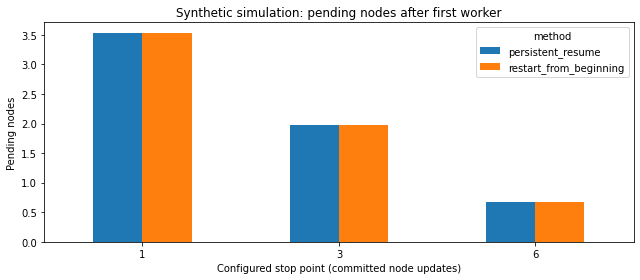

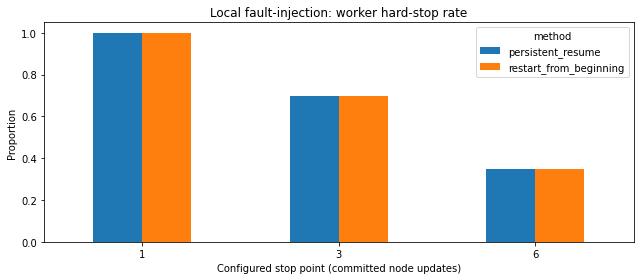

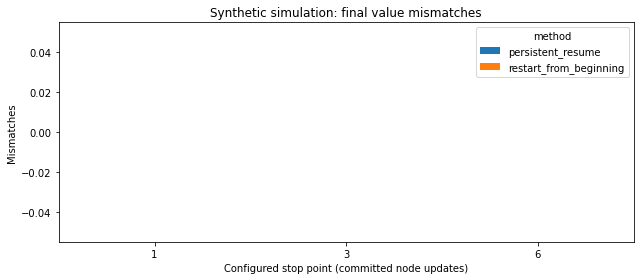

In [8]:
summary_df = results_df.groupby(["crash_after_writes","method"]).agg(
    mean_first_pending=("first_pending_nodes","mean"),
    mean_final_pending=("final_pending_nodes","mean"),
    mean_final_value_mismatches=("final_value_mismatches","mean"),
    final_integrity_pass_rate=("final_integrity_valid","mean"),
    hard_stop_rate=("first_worker_exit_code", lambda s: (s == 86).mean())
).reset_index()
display(summary_df)

for metric, title, ylabel in [
    ("mean_first_pending", "Synthetic simulation: pending nodes after first worker", "Pending nodes"),
    ("hard_stop_rate", "Local fault-injection: worker hard-stop rate", "Proportion"),
    ("mean_final_value_mismatches", "Synthetic simulation: final value mismatches", "Mismatches")
]:
    pivot = summary_df.pivot(index="crash_after_writes", columns="method", values=metric)
    ax = pivot.plot(kind="bar", figsize=(9,4))
    ax.set_title(title)
    ax.set_xlabel("Configured stop point (committed node updates)")
    ax.set_ylabel(ylabel)
    ax.tick_params(axis="x", rotation=0)
    plt.tight_layout()
    plt.show()

print("Interpretation: any difference is specific to this synthetic workload and worker implementation.")

## 9. Export CSVs and audit database

In [9]:
results_df.to_csv("trustsr_lab08_hard_crash_trials.csv", index=False)
summary_df.to_csv("trustsr_lab08_hard_crash_summary.csv", index=False)
integrity_df.to_csv("trustsr_lab08_integrity_injection_tests.csv", index=False)

for name in [
    "trustsr_lab08_hard_crash_trials.csv",
    "trustsr_lab08_hard_crash_summary.csv",
    "trustsr_lab08_integrity_injection_tests.csv",
    str(DB_PATH)
]:
    print("Created:", name, "| bytes:", Path(name).stat().st_size)

print("Evidence classification: synthetic state data + actual local subprocess termination.")
print("No claim is made about VM reset, power loss, storage hardware, or production deployment.")

Created: trustsr_lab08_hard_crash_trials.csv | bytes: 21954
Created: trustsr_lab08_hard_crash_summary.csv | bytes: 478
Created: trustsr_lab08_integrity_injection_tests.csv | bytes: 448
Created: trustsr_lab08_crash_recovery.sqlite3 | bytes: 1413120
Evidence classification: synthetic state data + actual local subprocess termination.
No claim is made about VM reset, power loss, storage hardware, or production deployment.


## 10. Interpretation limits and publication wording

### What this lab can support
- The worker process was forcibly terminated at controlled points in a local experiment.
- A fresh worker process reopened SQLite and resumed from persisted journal entries.
- Independent validation detected the specific logical inconsistencies injected by this notebook.
- Trial counts, process exit codes, pending nodes, final mismatches, and validator outcomes are exported.

### What this lab cannot support
- Survival of a Colab VM reset, physical power failure, kernel panic, storage controller failure, or filesystem corruption.
- Comprehensive detection of arbitrary tampering, malicious snapshot replacement, concurrent writers, or distributed recovery failures.
- Cryptographic authenticity, correct contamination planning, or correctness of real agent recovery.
- General superiority outside the tested synthetic workload.

### Publication wording
“We evaluated a local SQLite-backed recovery prototype using synthetic state and actual worker-process termination at controlled points. A fresh worker process resumed from the persisted journal, and an independent validator checked state/journal consistency. Results are limited to this implementation and runtime; they do not establish resilience to hardware failure or production effectiveness.”

### Completion checklist
- All assertions pass.
- Three CSV files exist.
- Integrity injection tests all report `detected=True`.
- Label all tables and plots as synthetic/local prototype.
- Review the executed notebook/PDF before citing any result.